<a href="https://colab.research.google.com/github/NguyenBaTam-tristan/Boston-housing-statistic-assignment/blob/main/Boston_Housing_Final_Assignment_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>

#### Import the required libraries we need for the lab.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL

In [2]:
boston_df=pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv')

# Boston Housing: Statistics for Data Science Final Assignment

In this notebook I analyze the Boston Housing dataset. The notebook has three parts:

1. Become familiar with the dataset
2. Generate descriptive statistics and visualizations
3. Use appropriate statistical tests to answer four questions

**Variables used in this notebook**

- **CHAS**: Charles River dummy variable (1 if the tract bounds the river, 0 otherwise)
- **NOX**: Nitric oxides concentration (parts per 10 million)
- **INDUS**: Proportion of non-retail business acres per town
- **AGE**: Proportion of owner-occupied units built prior to 1940
- **DIS**: Weighted distances to five Boston employment centres
- **PTRATIO**: Pupil-teacher ratio by town
- **MEDV**: Median value of owner-occupied homes in $1000's

## Task 1 and 2: Become familiar with the dataset and load it

In [3]:
# Size of the dataset and the first rows
print(boston_df.shape)
boston_df.head()

(506, 14)


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


In [4]:
# Data types of all the columns
boston_df.dtypes

,0
Unnamed: 0,int64
CRIM,float64
ZN,float64
INDUS,float64
CHAS,float64
NOX,float64
RM,float64
AGE,float64
DIS,float64
RAD,float64


In [5]:
# More information about the columns
boston_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  506 non-null    int64  
 1   CRIM        506 non-null    float64
 2   ZN          506 non-null    float64
 3   INDUS       506 non-null    float64
 4   CHAS        506 non-null    float64
 5   NOX         506 non-null    float64
 6   RM          506 non-null    float64
 7   AGE         506 non-null    float64
 8   DIS         506 non-null    float64
 9   RAD         506 non-null    float64
 10  TAX         506 non-null    float64
 11  PTRATIO     506 non-null    float64
 12  LSTAT       506 non-null    float64
 13  MEDV        506 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 55.5 KB


### Check for missing values in each column

In [6]:
boston_df.isnull().sum()

,0
Unnamed: 0,0
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0


### Check for duplicate rows

In [7]:
print('Number of duplicate rows:', boston_df.duplicated().sum())
boston_df[boston_df.duplicated()]

Number of duplicate rows: 0


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV


### Correlation matrix of the dataset

In [8]:
corr_matrix = boston_df.drop(columns=['Unnamed: 0'], errors='ignore').corr(numeric_only=True)
corr_matrix

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
CRIM,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305
ZN,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445
INDUS,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725
CHAS,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260
NOX,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321
RM,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360
AGE,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955
DIS,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929
RAD,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626
TAX,0.582764,-0.314563,0.720760,-0.035587,0.668023,-0.292048,0.506456,-0.534432,0.910228,1.000000,0.460853,0.543993,-0.468536


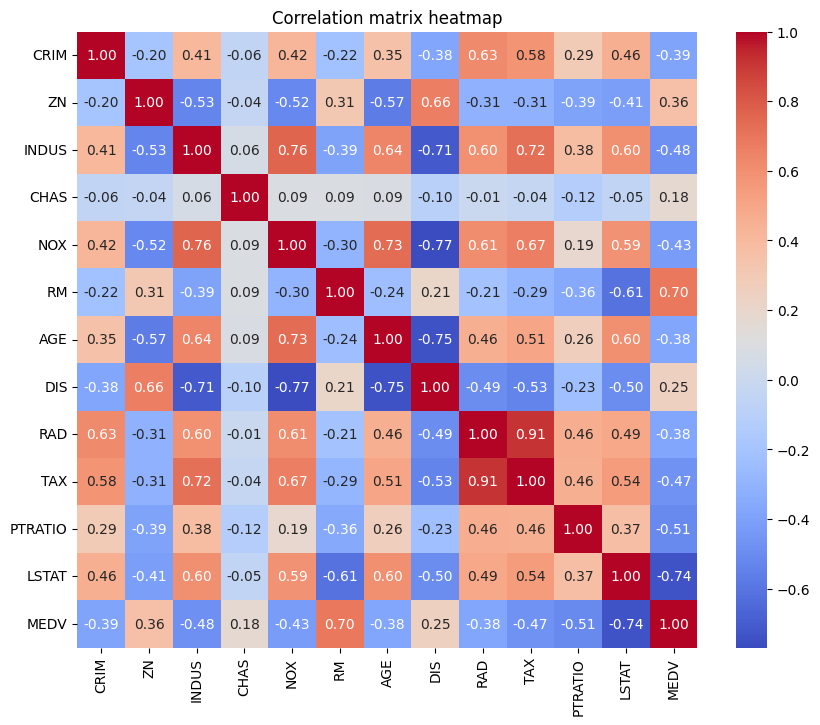

In [9]:
pyplot.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
pyplot.title('Correlation matrix heatmap')
pyplot.show()

**Observation:** The matrix shows how strongly each pair of numeric variables is related. For example, NOX and INDUS have a strong positive correlation, and MEDV is strongly related to variables such as RM and LSTAT.

In [10]:
# Descriptive statistics for every numeric column
boston_df.describe()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


## Task 3: Descriptive statistics and visualizations

### 3.1 Boxplot of the median value of owner-occupied homes (MEDV)

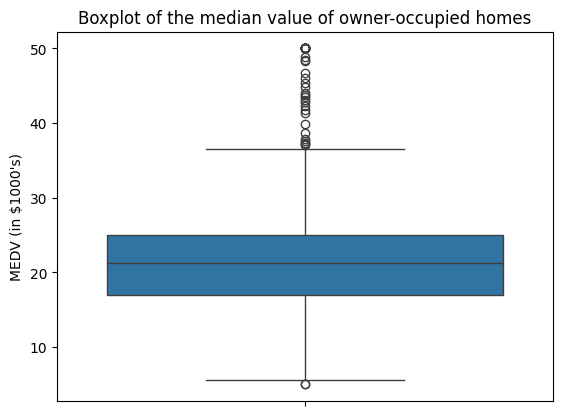

In [11]:
sns.boxplot(y='MEDV', data=boston_df)
pyplot.title('Boxplot of the median value of owner-occupied homes')
pyplot.ylabel('MEDV (in $1000\'s)')
pyplot.show()

**Observation:** The median value of homes is centered around 21 to 22 thousand dollars. The boxplot shows several outliers on the high end, which are the most expensive tracts.

### 3.2 Bar chart for the Charles River variable (CHAS)

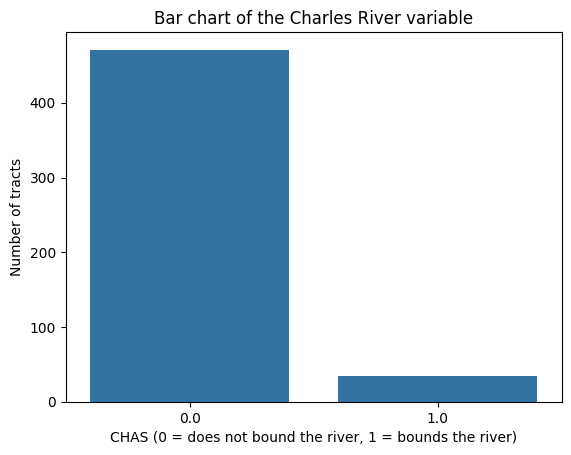

In [12]:
sns.countplot(x='CHAS', data=boston_df)
pyplot.title('Bar chart of the Charles River variable')
pyplot.xlabel('CHAS (0 = does not bound the river, 1 = bounds the river)')
pyplot.ylabel('Number of tracts')
pyplot.show()

**Observation:** Most tracts do not bound the Charles River. Only a small number of tracts (CHAS = 1) are next to the river.

### 3.3 Boxplot of MEDV vs AGE (discretized into three groups)

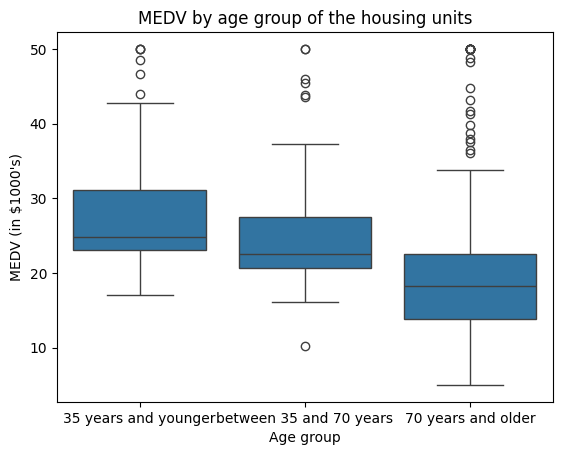

In [13]:
# Discretize AGE into three groups
boston_df.loc[(boston_df['AGE'] <= 35), 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70 years'
boston_df.loc[(boston_df['AGE'] >= 70), 'age_group'] = '70 years and older'

order = ['35 years and younger', 'between 35 and 70 years', '70 years and older']
sns.boxplot(x='age_group', y='MEDV', data=boston_df, order=order)
pyplot.title('MEDV by age group of the housing units')
pyplot.xlabel('Age group')
pyplot.ylabel('MEDV (in $1000\'s)')
pyplot.show()

**Observation:** Median home values are highest for the group with the newest housing units (35 years and younger) and lowest for the group with the oldest units (70 years and older). The group in the middle falls in between.

### 3.4 Scatter plot of NOX vs INDUS

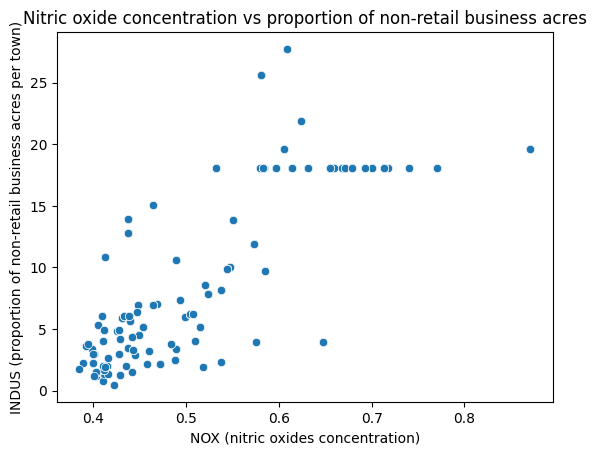

In [14]:
sns.scatterplot(x='NOX', y='INDUS', data=boston_df)
pyplot.title('Nitric oxide concentration vs proportion of non-retail business acres')
pyplot.xlabel('NOX (nitric oxides concentration)')
pyplot.ylabel('INDUS (proportion of non-retail business acres per town)')
pyplot.show()

**Observation:** There is a positive relationship between the two variables. Towns with a larger proportion of non-retail business acres tend to have higher nitric oxide concentrations.

### 3.5 Histogram for the pupil to teacher ratio (PTRATIO)

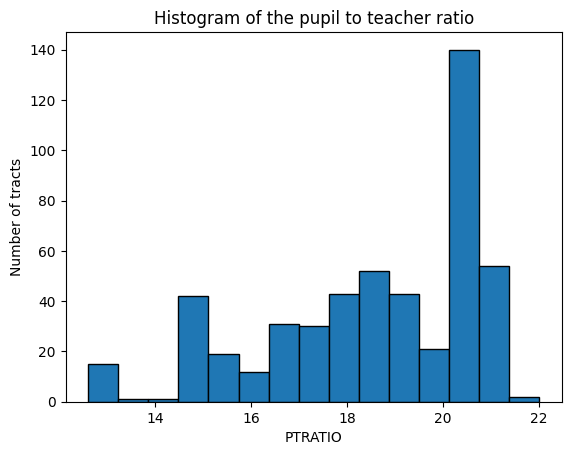

In [15]:
pyplot.hist(boston_df['PTRATIO'], bins=15, edgecolor='black')
pyplot.title('Histogram of the pupil to teacher ratio')
pyplot.xlabel('PTRATIO')
pyplot.ylabel('Number of tracts')
pyplot.show()

**Observation:** The pupil to teacher ratio is not symmetric. Many tracts have a ratio around 20 to 21, and the ratio is lower in a smaller number of tracts.

## Task 4: Hypothesis tests

All tests use a significance level of **alpha = 0.05**.

### 4.1 Levene's test: are the variances of MEDV equal for houses bounded by the Charles River (CHAS = 1) and houses that are not (CHAS = 0)?

**Test:** Levene's test for equality of variances

- **H0:** The variances of MEDV are equal in the two groups.
- **H1:** The variances of MEDV are not equal in the two groups.

In [16]:
chas_yes = boston_df[boston_df['CHAS'] == 1]['MEDV']
chas_no = boston_df[boston_df['CHAS'] == 0]['MEDV']

levene_stat, levene_p = scipy.stats.levene(chas_yes, chas_no, center='mean')
print('Levene test statistic: {}'.format(levene_stat))
print('Levene p-value: {}'.format(levene_p))

# Decide which version of the t-test to use in the next step
equal_var = levene_p > 0.05
print('Assume equal variances:', equal_var)

Levene test statistic: 8.75190489604598
Levene p-value: 0.003238119367639829
Assume equal variances: False


**Interpretation:** We compare the p-value of Levene's test with alpha = 0.05. If the p-value is below 0.05, we reject H0, the variances are not equal, and the next t-test uses the unequal variance version (Welch's t-test). If the p-value is above 0.05, we do not reject H0 and the t-test assumes equal variances. The code above makes this choice with the `equal_var` variable.

### 4.2 Is there a significant difference in the median value of houses bounded by the Charles River or not?

**Test:** T-test for independent samples

- **H0:** There is no difference in the mean MEDV between tracts that bound the Charles River and tracts that do not (mu1 = mu2).
- **H1:** There is a difference in the mean MEDV between the two groups (mu1 != mu2).

In [17]:
t_stat, t_p = scipy.stats.ttest_ind(chas_yes, chas_no, equal_var=equal_var)
print('T-statistic: {}'.format(t_stat))
print('p-value: {}'.format(t_p))

T-statistic: 3.113291312794837
p-value: 0.0035671700981375174


**Conclusion:** The p-value of the t-test is much smaller than 0.05, so we reject the null hypothesis. There is a statistically significant difference in the median value of houses bounded by the Charles River and houses that are not. Houses next to the river have a higher mean MEDV.

### 4.3 Is there a difference in the median values of houses (MEDV) for each proportion of owner-occupied units built prior to 1940 (AGE)?

**Test:** One-way ANOVA (three age groups)

- **H0:** The mean MEDV is the same in all three age groups (mu1 = mu2 = mu3).
- **H1:** At least one age group has a different mean MEDV.

In [18]:
young = boston_df[boston_df['age_group'] == '35 years and younger']['MEDV']
middle = boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV']
old = boston_df[boston_df['age_group'] == '70 years and older']['MEDV']

# Levene's test for equality of variances across the three groups
print("Levene's test:", scipy.stats.levene(young, middle, old, center='mean'))

f_statistic, p_value = scipy.stats.f_oneway(young, middle, old)
print('F-statistic: {}, p-value: {}'.format(f_statistic, p_value))

Levene's test: LeveneResult(statistic=np.float64(2.7806200293748304), pvalue=np.float64(0.06295337343259205))
F-statistic: 36.40764999196598, p-value: 1.7105011022702984e-15


**Conclusion:** The p-value of the ANOVA test is far below 0.05, so we reject the null hypothesis. There is a statistically significant difference in the median value of houses across the three age groups.

### 4.4 Can we conclude that there is no relationship between nitric oxide concentrations and the proportion of non-retail business acres per town?

**Test:** Pearson correlation

- **H0:** NOX and INDUS are not correlated (the correlation is 0).
- **H1:** NOX and INDUS are correlated (the correlation is not 0).

In [19]:
corr, p_value = scipy.stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])
print('Pearson correlation: {}, p-value: {}'.format(corr, p_value))

Pearson correlation: 0.7636514469209154, p-value: 7.913361061239639e-98


**Conclusion:** The p-value is far below 0.05, so we reject the null hypothesis. We cannot conclude that there is no relationship. There is a statistically significant and strong positive correlation between nitric oxide concentrations and the proportion of non-retail business acres per town, which agrees with the scatter plot.

### 4.5 What is the impact of an additional weighted distance to the five Boston employment centres on the median value of owner-occupied homes?

**Test:** Simple linear regression (MEDV as the response, DIS as the predictor)

- **H0:** The slope of DIS is 0 (DIS has no effect on MEDV).
- **H1:** The slope of DIS is not 0.

In [20]:
X = sm.add_constant(boston_df['DIS'])
y = boston_df['MEDV']
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        05:42:11   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

In [21]:
print('Intercept:', model.params['const'])
print('Slope for DIS:', model.params['DIS'])
print('R-squared:', model.rsquared)
print('p-value for DIS:', model.pvalues['DIS'])

Intercept: 18.39008833049339
Slope for DIS: 1.0916130158411075
R-squared: 0.062464372121782574
p-value for DIS: 1.2066117273371793e-08


**Conclusion:** The p-value of the DIS coefficient is below 0.05, so we reject the null hypothesis. The weighted distance to the five Boston employment centres has a statistically significant positive effect on the median value of homes: for each additional unit of weighted distance, the median home value increases on average by the value of the DIS slope shown above (in $1000's). The R-squared is small, so distance explains only a small part of the variation in home values, and other variables matter as well.